# 01 · Data Quality & Exploratory Analysis
**Retail Demand Forecasting — Store Item Demand (10 stores × 50 items, daily, 2013–2017)**

**Author: Anurag Moyal**

**Business context.** A retailer needs to know how many units of each item every store will sell over the next
quarter, so it can order the right stock: too little means lost sales, too much ties up cash and creates waste.
Before modelling, this notebook audits the data and learns the patterns a forecast must capture —
**trend, weekly rhythm and yearly seasonality**.

**Questions**
1. Is the data complete and trustworthy?
2. How fast is demand growing, and is the growth stable?
3. What are the weekly and yearly patterns, and are they the same across stores / items?
4. Is the series stationary (matters for ARIMA)?
5. Where is the volume concentrated (which stores and items drive the forecast error that matters)?

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC, FIG = ROOT / "data/raw/train.csv", ROOT / "data/processed", ROOT / "reports/figures"
PROC.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
BLUE, ORANGE, GREEN, RED, GREY = "#2F5D8A", "#E08A2E", "#2E8B57", "#C0392B", "#8A8F98"
def save(n): plt.tight_layout(); plt.savefig(FIG / f"{n}.png", dpi=150, bbox_inches="tight"); plt.show()

df = pd.read_csv(RAW, parse_dates=["date"])
print(f"{len(df):,} rows · {df.store.nunique()} stores × {df.item.nunique()} items · {df.date.min().date()} → {df.date.max().date()}")
df.head()

913,000 rows · 10 stores × 50 items · 2013-01-01 → 2017-12-31


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


## 1. Data-quality audit

In [2]:
n_days = (df.date.max() - df.date.min()).days + 1
audit = {
    "Rows": len(df),
    "Expected rows (stores × items × days)": df.store.nunique() * df.item.nunique() * n_days,
    "Missing values": int(df.isna().sum().sum()),
    "Duplicate (date, store, item) keys": int(df.duplicated(["date", "store", "item"]).sum()),
    "Negative sales": int((df.sales < 0).sum()),
    "Zero-sales days": int((df.sales == 0).sum()),
    "Series with a gap in dates": int((df.groupby(["store", "item"]).date.nunique() != n_days).sum()),
}
print(pd.Series(audit).to_string())
print("\nSales per store-item-day:"); print(df.sales.describe().round(2).to_string())

Rows                                     913000
Expected rows (stores × items × days)    913000
Missing values                                0
Duplicate (date, store, item) keys            0
Negative sales                                0
Zero-sales days                               1
Series with a gap in dates                    0

Sales per store-item-day:
count    913000.00
mean         52.25
std          28.80
min           0.00
25%          30.00
50%          47.00
75%          70.00
max         231.00


**Verdict:** the panel is complete (no gaps, no duplicates, no negatives), so no imputation is needed — an unusually clean dataset.
The few zero-sales days are real (low-volume items); this matters for the choice of metric: **MAPE is undefined at zero and
explodes for tiny values**, so we report MAPE only over non-zero days and add **WAPE** (sum of errors ÷ sum of sales) and
**MASE** as robust alternatives.

## 2. Total demand — trend & growth

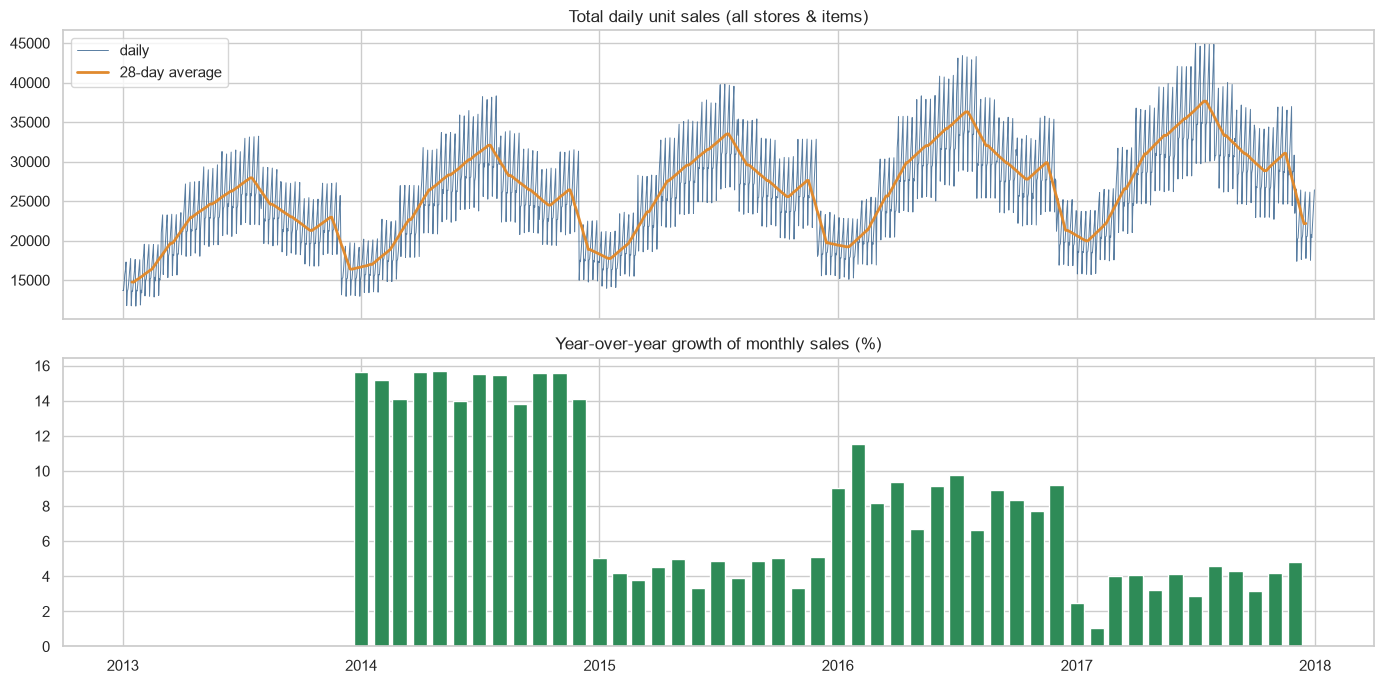

date
2014    15.0
2015     4.4
2016     8.6
2017     3.6


In [3]:
tot = df.groupby("date").sales.sum().asfreq("D")
tot.to_csv(PROC / "total_daily_sales.csv")
fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
ax[0].plot(tot.index, tot, color=BLUE, lw=.7, alpha=.8, label="daily")
ax[0].plot(tot.rolling(28, center=True).mean(), color=ORANGE, lw=2, label="28-day average")
ax[0].set_title("Total daily unit sales (all stores & items)"); ax[0].legend()
yoy = tot.resample("MS").sum().pct_change(12) * 100
ax[1].bar(yoy.index, yoy, width=22, color=[GREEN if v >= 0 else RED for v in yoy.fillna(0)]); ax[1].set_title("Year-over-year growth of monthly sales (%)")
save("01_total_demand_trend")
yearly = tot.groupby(tot.index.year).sum()
print((yearly.pct_change() * 100).round(1).dropna().rename("YoY growth %").to_string())

## 3. Seasonality — weekly and yearly patterns

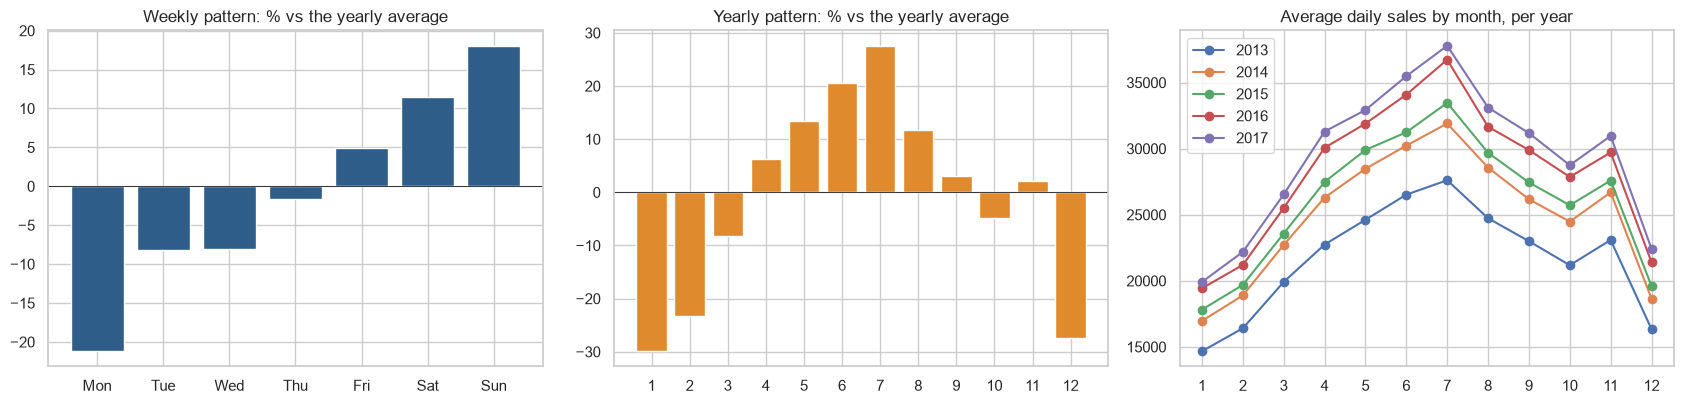

In [4]:
d = tot.to_frame("sales"); d["dow"] = d.index.dayofweek; d["month"] = d.index.month; d["year"] = d.index.year
d["rel"] = d.sales / d.sales.rolling(365, center=True, min_periods=180).mean()          # remove trend before comparing
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
w = d.groupby("dow").rel.mean(); ax[0].bar(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], (w - 1) * 100, color=BLUE)
ax[0].set_title("Weekly pattern: % vs the yearly average"); ax[0].axhline(0, color="k", lw=.6)
m = d.groupby("month").rel.mean(); ax[1].bar(range(1, 13), (m - 1) * 100, color=ORANGE)
ax[1].set_title("Yearly pattern: % vs the yearly average"); ax[1].set_xticks(range(1, 13)); ax[1].axhline(0, color="k", lw=.6)
piv = d.pivot_table(index="month", columns="year", values="sales", aggfunc="mean")
for y in piv.columns: ax[2].plot(piv.index, piv[y], marker="o", label=y)
ax[2].set_title("Average daily sales by month, per year"); ax[2].legend(); ax[2].set_xticks(range(1, 13))
save("02_seasonality")

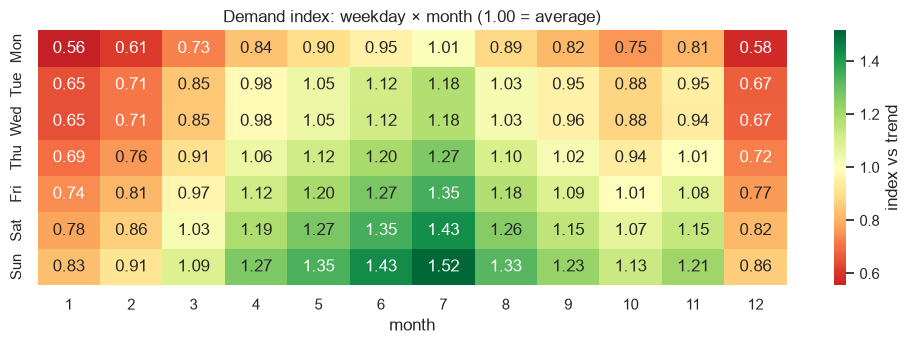

Peak month index 1.28 (7), trough 0.70 (1) · weekend uplift: Sun 1.18 vs Mon 0.79


In [5]:
hm = d.dropna().pivot_table(index="dow", columns="month", values="rel", aggfunc="mean")
fig, ax = plt.subplots(figsize=(10, 3.6))
sns.heatmap(hm, cmap="RdYlGn", center=1, annot=True, fmt=".2f", ax=ax, yticklabels=["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], cbar_kws={"label": "index vs trend"})
ax.set_title("Demand index: weekday × month (1.00 = average)"); ax.set_xlabel("month"); ax.set_ylabel("")
save("03_weekday_month_heatmap")
print(f"Peak month index {m.max():.2f} ({m.idxmax()}), trough {m.min():.2f} ({m.idxmin()}) · weekend uplift: Sun {w.iloc[6]:.2f} vs Mon {w.iloc[0]:.2f}")

### STL decomposition (trend + seasonal + residual)
Two seasonalities (7 and 365 days) coexist, so models must handle *multiple seasonal periods* — plain ARIMA/ETS with a single period cannot.

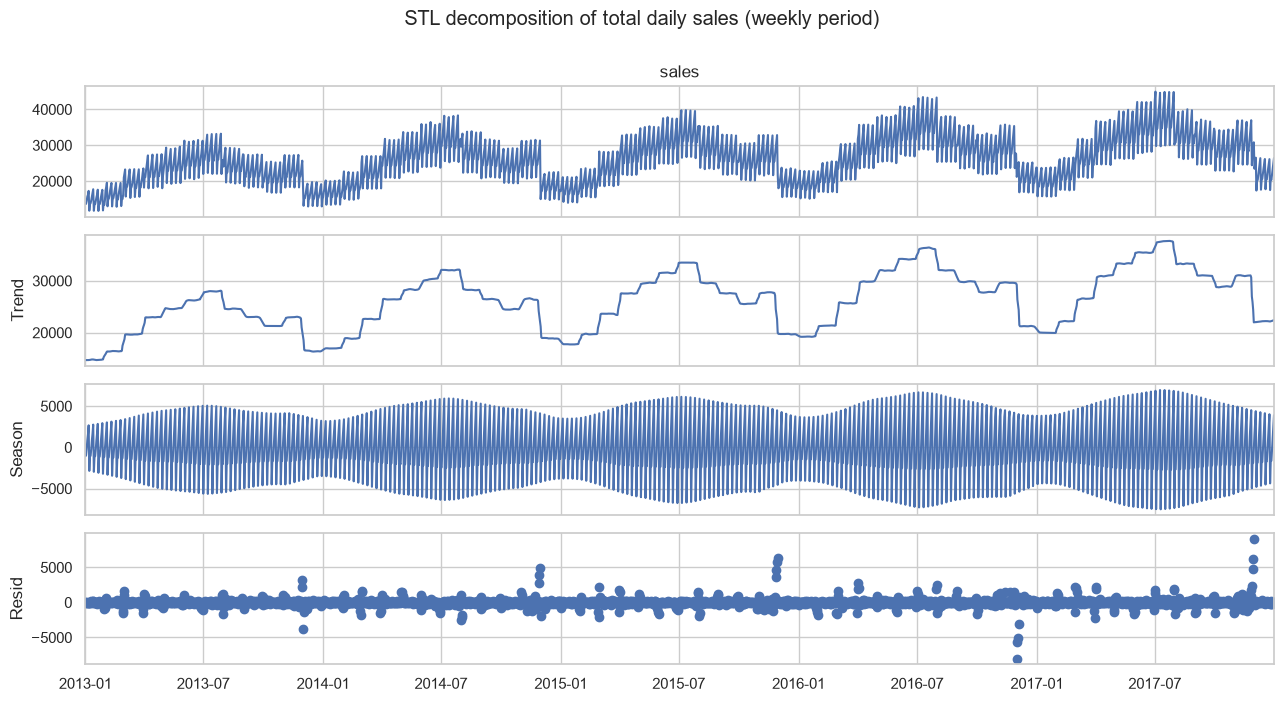

Residual std = 673 units/day = 2.6% of average daily demand → the noise floor no model can beat by much


In [6]:
stl = STL(tot, period=7, seasonal=13, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(13, 7); fig.suptitle("STL decomposition of total daily sales (weekly period)", y=1.0)
save("04_stl_decomposition")
res = stl.resid
print(f"Residual std = {res.std():,.0f} units/day = {res.std()/tot.mean():.1%} of average daily demand → the noise floor no model can beat by much")

## 4. Stationarity & autocorrelation

In [7]:
rows = []
for name, s in [("Total sales", tot), ("1st difference", tot.diff().dropna()), ("7-day seasonal difference", tot.diff(7).dropna())]:
    adf, kp = adfuller(s, autolag="AIC")[1], kpss(s, nlags="auto")[1]
    rows.append(dict(series=name, ADF_p=adf, KPSS_p=kp, verdict="stationary" if (adf < .05 and kp > .05) else "non-stationary / mixed"))
pd.DataFrame(rows).set_index("series").style.format({"ADF_p": "{:.4f}", "KPSS_p": "{:.4f}"})

,ADF_p,KPSS_p,verdict
series,,,
Total sales,0.0296,0.0100,non-stationary / mixed
1st difference,0.0000,0.1000,stationary
7-day seasonal difference,0.0000,0.1000,stationary


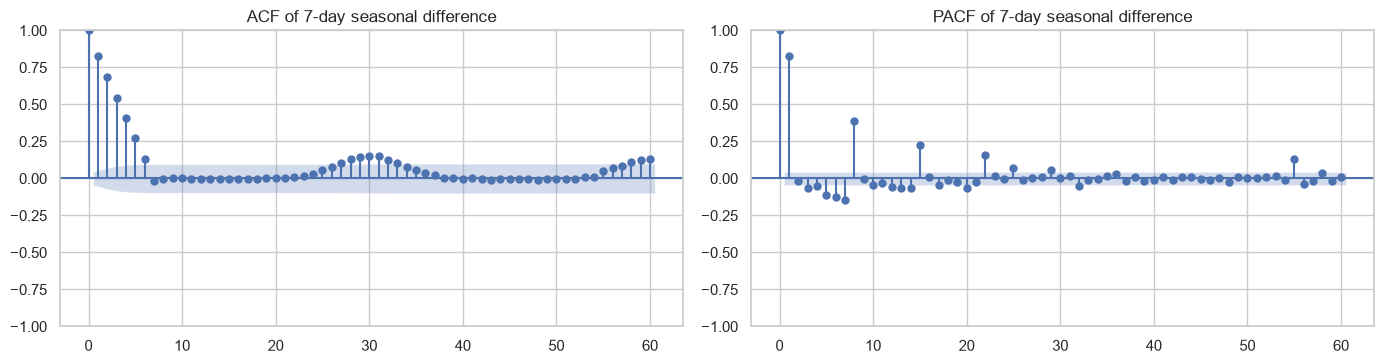

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
plot_acf(tot.diff(7).dropna(), lags=60, ax=ax[0]); ax[0].set_title("ACF of 7-day seasonal difference")
plot_pacf(tot.diff(7).dropna(), lags=60, ax=ax[1], method="ywm"); ax[1].set_title("PACF of 7-day seasonal difference")
save("05_acf_pacf")

**Reading:** the raw series is non-stationary (trend), a first difference or a 7-day seasonal difference removes most of it, and the
autocorrelation shows spikes at lags 7, 14, 21… (weekly cycle). That motivates a **SARIMA-type model with seasonal period 7
plus annual Fourier terms**, which we test in notebook 02.

## 5. Where is the volume? Stores, items and ABC classes

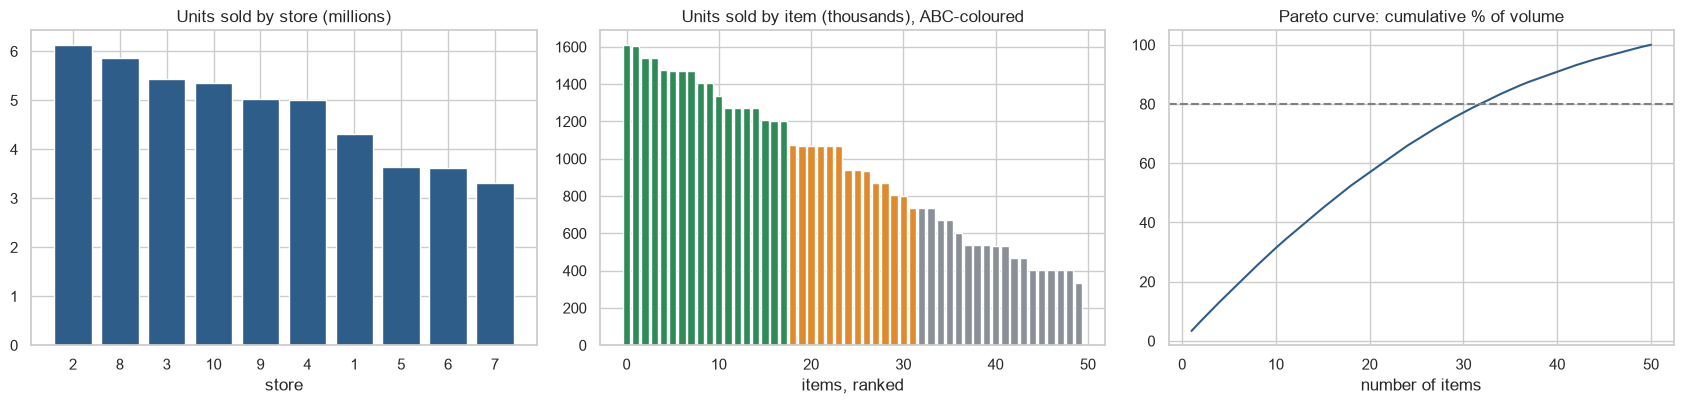

sales
A (top 50% of volume)    18
B (next 30%)             14
C (last 20%)             18

Biggest store sells 1.84× the smallest; biggest item 4.80× the smallest.


In [9]:
store = df.groupby("store").sales.sum().sort_values(ascending=False)
item = df.groupby("item").sales.sum().sort_values(ascending=False)
cum = item.cumsum() / item.sum()
abc = pd.cut(cum.shift(fill_value=0), [-.01, .5, .8, 1.0], labels=["A (top 50% of volume)", "B (next 30%)", "C (last 20%)"])
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].bar(store.index.astype(str), store / 1e6, color=BLUE); ax[0].set_title("Units sold by store (millions)"); ax[0].set_xlabel("store")
ax[1].bar(range(len(item)), item.values / 1e3, color=[{"A":GREEN,"B":ORANGE,"C":GREY}[str(a)[0]] for a in abc]); ax[1].set_title("Units sold by item (thousands), ABC-coloured"); ax[1].set_xlabel("items, ranked")
ax[2].plot(range(1, len(cum) + 1), cum.values * 100, color=BLUE); ax[2].axhline(80, ls="--", color="grey"); ax[2].set_title("Pareto curve: cumulative % of volume"); ax[2].set_xlabel("number of items")
save("06_store_item_volume")
print(abc.value_counts().sort_index().to_string())
print(f"\nBiggest store sells {store.iloc[0]/store.iloc[-1]:.2f}× the smallest; biggest item {item.iloc[0]/item.iloc[-1]:.2f}× the smallest.")

In [10]:
ratio = df.assign(month=df.date.dt.month).groupby(["store", "month"]).sales.mean().unstack()
ratio = ratio.div(ratio.mean(axis=1), axis=0)
ri = df.assign(month=df.date.dt.month).groupby(["item", "month"]).sales.mean().unstack(); ri = ri.div(ri.mean(axis=1), axis=0)
print(f"Seasonal shape is near-identical across stores (max spread of a month index = {ratio.std().max():.3f}) "
      f"and across items ({ri.std().max():.3f}) — a global model can share seasonality across all 500 series.\n"
      "(Such uniform seasonality suggests the competition data is partly simulated; real retail data is usually messier.)")

Seasonal shape is near-identical across stores (max spread of a month index = 0.002) and across items (0.005) — a global model can share seasonality across all 500 series.
(Such uniform seasonality suggests the competition data is partly simulated; real retail data is usually messier.)


## 6. Key findings

In [11]:
g = yearly.pct_change().dropna() * 100
print(f"""1. The panel is complete: {len(df):,} rows, no gaps / duplicates / negatives.
2. Demand grows every year ({', '.join(f'{y}: +{v:.1f}%' for y, v in g.items())}) — a trend component is essential.
3. Strong weekly cycle (Sunday ≈ {w.iloc[6]:.2f}× vs Monday ≈ {w.iloc[0]:.2f}× of average) and strong yearly seasonality
   (peak month index {m.max():.2f} vs trough {m.min():.2f}) — two seasonal periods, so plain single-period ARIMA/ETS will struggle.
4. Seasonal shape is shared across all stores and items; volume level differs ({store.iloc[0]/store.iloc[-1]:.1f}× between stores,
   {item.iloc[0]/item.iloc[-1]:.1f}× between items) → model the shape globally, scale per series.
5. Item volume is moderately concentrated ({int((cum <= .5).sum()) + 1} of 50 items make 50% of units), so forecast accuracy on
   high-volume items drives most of the business value — hence WAPE (volume-weighted) is the headline metric next to MAPE.
6. Irreducible noise ≈ {res.std()/tot.mean():.1%} of daily total demand: sets realistic expectations for accuracy.""")

1. The panel is complete: 913,000 rows, no gaps / duplicates / negatives.
2. Demand grows every year (2014: +15.0%, 2015: +4.4%, 2016: +8.6%, 2017: +3.6%) — a trend component is essential.
3. Strong weekly cycle (Sunday ≈ 1.18× vs Monday ≈ 0.79× of average) and strong yearly seasonality
   (peak month index 1.28 vs trough 0.70) — two seasonal periods, so plain single-period ARIMA/ETS will struggle.
4. Seasonal shape is shared across all stores and items; volume level differs (1.8× between stores,
   4.8× between items) → model the shape globally, scale per series.
5. Item volume is moderately concentrated (18 of 50 items make 50% of units), so forecast accuracy on
   high-volume items drives most of the business value — hence WAPE (volume-weighted) is the headline metric next to MAPE.
6. Irreducible noise ≈ 2.6% of daily total demand: sets realistic expectations for accuracy.
